# Network Protocol Classification

This notebook explores the dataset and trains machine-learning models to classify network protocols.

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## 2. Load the Dataset

In [140]:
df = pd.read_csv("/content/KT_GameBox_All_Merged.csv")

### Dataset Overview

In [141]:
df.head()

,No.,Time,Source,Destination,Protocol,Length,Info,Hour,Minute,Second
0,1,2022-10-05 14:28:49.564595,192.0.0.2,10.215.173.2,TCP,60,47254 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...,14,28,49
1,2,2022-10-05 14:28:51.317163,10.215.173.1,10.215.173.2,DNS,68,Standard query 0xa610 A gbc.play.ktgamebox.com,14,28,51
2,3,2022-10-05 14:28:51.348247,10.215.173.2,10.215.173.1,DNS,168,Standard query response 0xa610 A gbc.play.ktga...,14,28,51
3,4,2022-10-05 14:28:51.351537,10.215.173.1,211.252.120.14,TCP,60,60014 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...,14,28,51
4,5,2022-10-05 14:28:51.372722,211.252.120.14,10.215.173.1,TCP,48,"443 > 60014 [SYN, ACK] Seq=0 Ack=1 Win=2048 ...",14,28,51


In [142]:
df.shape

(4965720, 10)

In [143]:
df.columns

Index(['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info',
       'Hour', 'Minute', 'Second'],
      dtype='object')

In [144]:
df.dtypes

,0
No.,int64
Time,object
Source,object
Destination,object
Protocol,object
Length,int64
Info,object
Hour,int64
Minute,int64
Second,int64


In [145]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4965720 entries, 0 to 4965719
Data columns (total 10 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   No.          int64 
 1   Time         object
 2   Source       object
 3   Destination  object
 4   Protocol     object
 5   Length       int64 
 6   Info         object
 7   Hour         int64 
 8   Minute       int64 
 9   Second       int64 
dtypes: int64(5), object(5)
memory usage: 378.9+ MB


In [146]:
df.describe()

,No.,Length,Hour,Minute,Second
count,4.965720e+06,4.965720e+06,4.965720e+06,4.965720e+06,4.965720e+06
mean,8.567004e+05,1.241464e+03,1.483159e+01,2.757176e+01,2.951280e+01
std,5.283638e+05,8.616636e+02,2.541558e+00,2.007631e+01,1.728011e+01
min,1.000000e+00,3.200000e+01,1.200000e+01,0.000000e+00,0.000000e+00
25%,4.138108e+05,1.300000e+03,1.300000e+01,1.000000e+01,1.500000e+01
50%,8.276205e+05,1.300000e+03,1.400000e+01,2.200000e+01,3.000000e+01
75%,1.241430e+06,1.300000e+03,1.800000e+01,4.900000e+01,4.400000e+01
max,2.085899e+06,1.000000e+04,1.900000e+01,5.900000e+01,5.900000e+01


In [147]:
df.isnull().sum()

,0
No.,0
Time,0
Source,0
Destination,0
Protocol,0
Length,0
Info,0
Hour,0
Minute,0
Second,0


## 3. Data Cleaning and Protocol Exploration

In [148]:
df = df.dropna(subset=["Protocol"])

In [149]:
df = df.dropna()

In [150]:
print("Dataset shape:", df.shape)

Dataset shape: (4965720, 10)


In [151]:
df["Protocol"].unique()

array(['TCP', 'DNS', 'TLSv1.3', 'TLSv1', 'UDP', 'TLSv1.2', 'THRIFT',
       'SMPP', 'FMTP'], dtype=object)

In [152]:
df["Protocol"].value_counts()

,count
Protocol,
UDP,4507410
TCP,454078
TLSv1,3013
TLSv1.3,1051
THRIFT,92
TLSv1.2,38
DNS,30
SMPP,7
FMTP,1


## 4. Protocol and Packet-Length Visualization

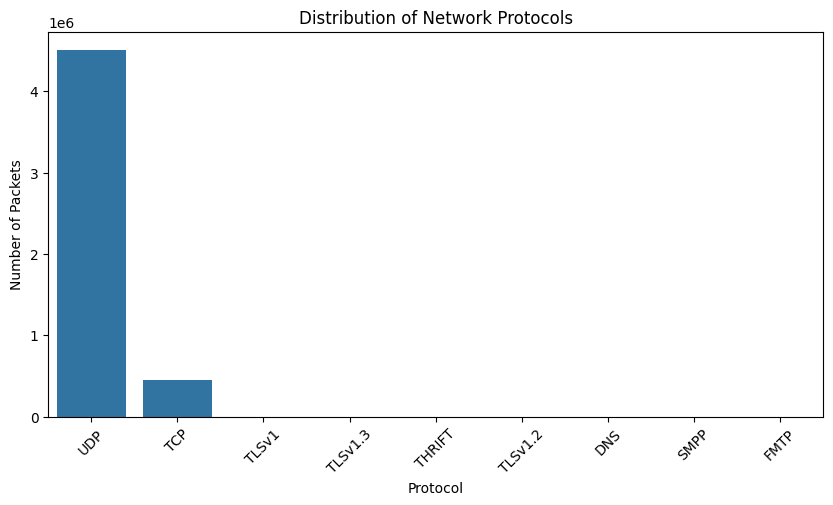

In [153]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")

plt.show()


In [154]:
df["Length"].describe()

,Length
count,4.965720e+06
mean,1.241464e+03
std,8.616636e+02
min,3.200000e+01
25%,1.300000e+03
50%,1.300000e+03
75%,1.300000e+03
max,1.000000e+04


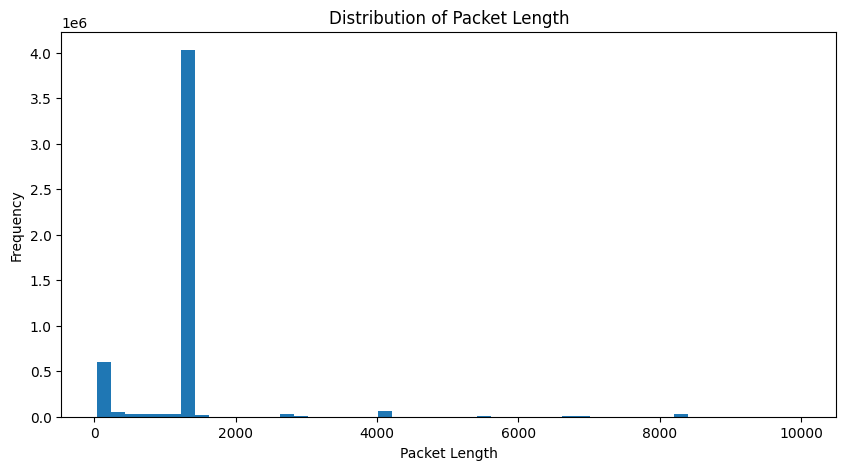

In [155]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()


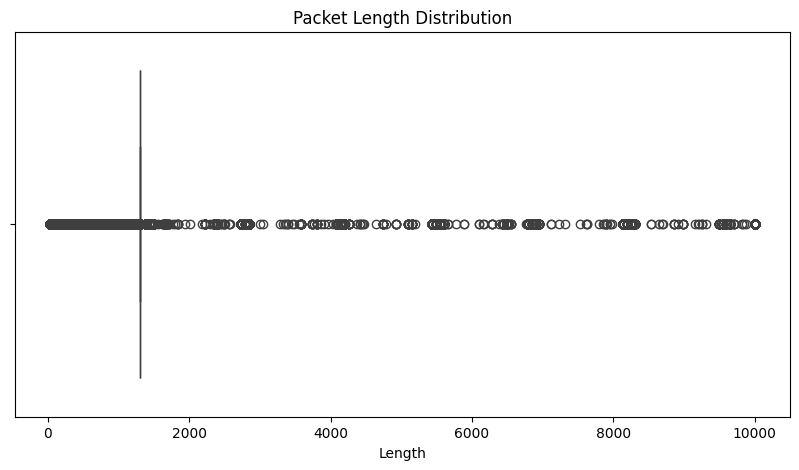

In [156]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")

plt.show()


## 5. Time-Based Feature Engineering

In [157]:
df["Time"].head()

,Time
0,2022-10-05 14:28:49.564595
1,2022-10-05 14:28:51.317163
2,2022-10-05 14:28:51.348247
3,2022-10-05 14:28:51.351537
4,2022-10-05 14:28:51.372722


In [158]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

In [159]:
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second


In [160]:
df[["Time", "Hour", "Minute", "Second"]].head()

,Time,Hour,Minute,Second
0,2022-10-05 14:28:49.564595,14,28,49
1,2022-10-05 14:28:51.317163,14,28,51
2,2022-10-05 14:28:51.348247,14,28,51
3,2022-10-05 14:28:51.351537,14,28,51
4,2022-10-05 14:28:51.372722,14,28,51


## 6. Prepare Features and Target

In [161]:
X = df[[
    "Length",
    "Hour",
    "Minute",
    "Second"
]]

y = df["Protocol"]


In [162]:
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)



Features:
   Length  Hour  Minute  Second
0      60    14      28      49
1      68    14      28      51
2     168    14      28      51
3      60    14      28      51
4      48    14      28      51

Target:
0    TCP
1    DNS
2    DNS
3    TCP
4    TCP
Name: Protocol, dtype: object
X shape: (4965720, 4)
y shape: (4965720,)


In [163]:
print(X.isnull().sum())
X = X.fillna(0)


Length    0
Hour      0
Minute    0
Second    0
dtype: int64


In [164]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)

print(y_encoded[:20])



['DNS' 'FMTP' 'SMPP' 'TCP' 'THRIFT' 'TLSv1' 'TLSv1.2' 'TLSv1.3' 'UDP']
[3 0 0 3 3 3 7 3 0 7 3 7 3 7 3 7 3 0 3 7]


## 7. Train-Test Split and Class Balancing

### Fixing the Stratified Split
We will remove protocol classes with fewer than 2 packets so we can successfully use stratified train-test splitting.

In [167]:
# Identify rare classes with fewer than 2 occurrences
protocol_counts = df["Protocol"].value_counts()
valid_protocols = protocol_counts[protocol_counts >= 2].index

# Filter the dataset to keep only valid protocols
df_filtered = df[df["Protocol"].isin(valid_protocols)]

# Re-extract features and target
X_filtered = df_filtered[["Length", "Hour", "Minute", "Second"]]
y_filtered = df_filtered["Protocol"]

# Re-encode labels
label_encoder_filtered = LabelEncoder()
y_encoded_filtered = label_encoder_filtered.fit_transform(y_filtered)

# Perform stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered,
    y_encoded_filtered,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded_filtered
)

print("Filtered Training samples:", X_train.shape[0])
print("Filtered Testing samples:", X_test.shape[0])

Filtered Training samples: 3972575
Filtered Testing samples: 993144


## 8. Feature Scaling

In [168]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


## 9. Logistic Regression

In [171]:
# Initialize a Decision Tree Classifier as an example
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluate the model using the correct filtered classes
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=label_encoder_filtered.classes_, zero_division=0))

Accuracy: 0.997970082888282

Classification Report:
               precision    recall  f1-score   support

         DNS       0.43      0.50      0.46         6
        SMPP       0.00      0.00      0.00         1
         TCP       0.99      0.99      0.99     90816
      THRIFT       0.00      0.00      0.00        18
       TLSv1       0.79      0.83      0.81       603
     TLSv1.2       0.29      0.25      0.27         8
     TLSv1.3       0.83      0.79      0.81       210
         UDP       1.00      1.00      1.00    901482

    accuracy                           1.00    993144
   macro avg       0.54      0.54      0.54    993144
weighted avg       1.00      1.00      1.00    993144



In [172]:

logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)


LogisticRegression(max_iter=1000)

In [173]:
y_pred_lr = logistic_model.predict(X_test_scaled)

In [174]:
accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr)


Logistic Regression Accuracy: 0.9162548432050136


In [175]:
print(
    "Accuracy:",
    accuracy_lr * 100,
    "%"
)


Accuracy: 91.62548432050136 %


In [177]:
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=label_encoder_filtered.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         6
        SMPP       0.00      0.00      0.00         1
         TCP       1.00      0.09      0.17     90816
      THRIFT       0.00      0.00      0.00        18
       TLSv1       0.00      0.00      0.00       603
     TLSv1.2       0.00      0.00      0.00         8
     TLSv1.3       0.00      0.00      0.00       210
         UDP       0.92      1.00      0.96    901482

    accuracy                           0.92    993144
   macro avg       0.24      0.14      0.14    993144
weighted avg       0.92      0.92      0.88    993144



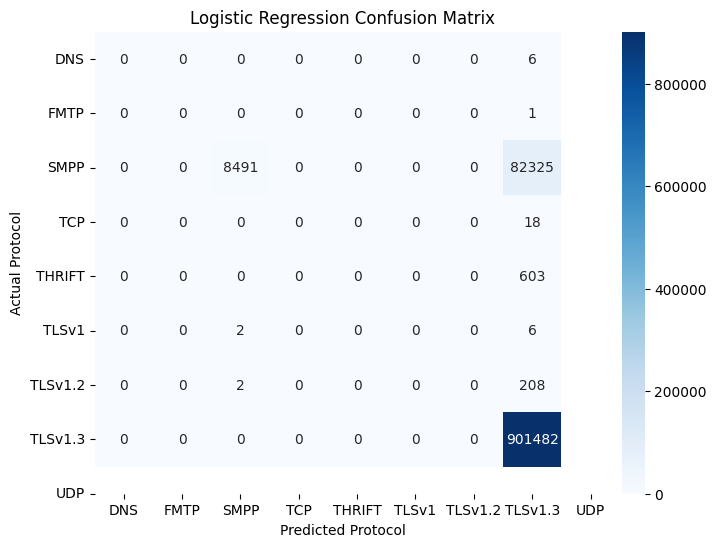

In [178]:
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")
plt.title("Logistic Regression Confusion Matrix")

plt.show()


## 10. K-Nearest Neighbors (KNN)

In [179]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)


KNeighborsClassifier()

In [181]:
# To avoid hanging due to the massive size of X_test_scaled (993,144 samples),
# we predict on a representative subset of 10,000 samples.
subset_size = 10000
X_test_scaled_subset = X_test_scaled[:subset_size]
y_test_subset = y_test[:subset_size]

y_pred_knn = knn_model.predict(X_test_scaled_subset)

In [184]:
accuracy_knn = accuracy_score(
    y_test_subset,
    y_pred_knn
)

print(
    "KNN Accuracy (on subset):",
    accuracy_knn * 100,
    "%"
)

KNN Accuracy (on subset): 99.56 %


In [185]:
import numpy as np

print("KNN Classification Report (on subset):\n")
# Generate class index labels [0, 1, ..., 7] corresponding to label_encoder_filtered
all_class_indices = np.arange(len(label_encoder_filtered.classes_))

print(
    classification_report(
        y_test_subset,
        y_pred_knn,
        labels=all_class_indices,
        target_names=label_encoder_filtered.classes_,
        zero_division=0
    )
)

KNN Classification Report (on subset):

              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         0
        SMPP       0.00      0.00      0.00         0
         TCP       0.97      0.99      0.98       939
      THRIFT       0.00      0.00      0.00         0
       TLSv1       0.00      0.00      0.00         4
     TLSv1.2       0.00      0.00      0.00         0
     TLSv1.3       0.00      0.00      0.00         0
         UDP       1.00      1.00      1.00      9057

    accuracy                           1.00     10000
   macro avg       0.25      0.25      0.25     10000
weighted avg       1.00      1.00      1.00     10000



## 11. Decision Tree Classifier

In [186]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

dt_model.fit(
    X_train,
    y_train
)


DecisionTreeClassifier(max_depth=10, random_state=42)

In [187]:
y_pred_dt = dt_model.predict(X_test)

In [188]:
accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(
    "Decision Tree Accuracy:",
    accuracy_dt * 100,
    "%"
)


Decision Tree Accuracy: 99.85007209427837 %


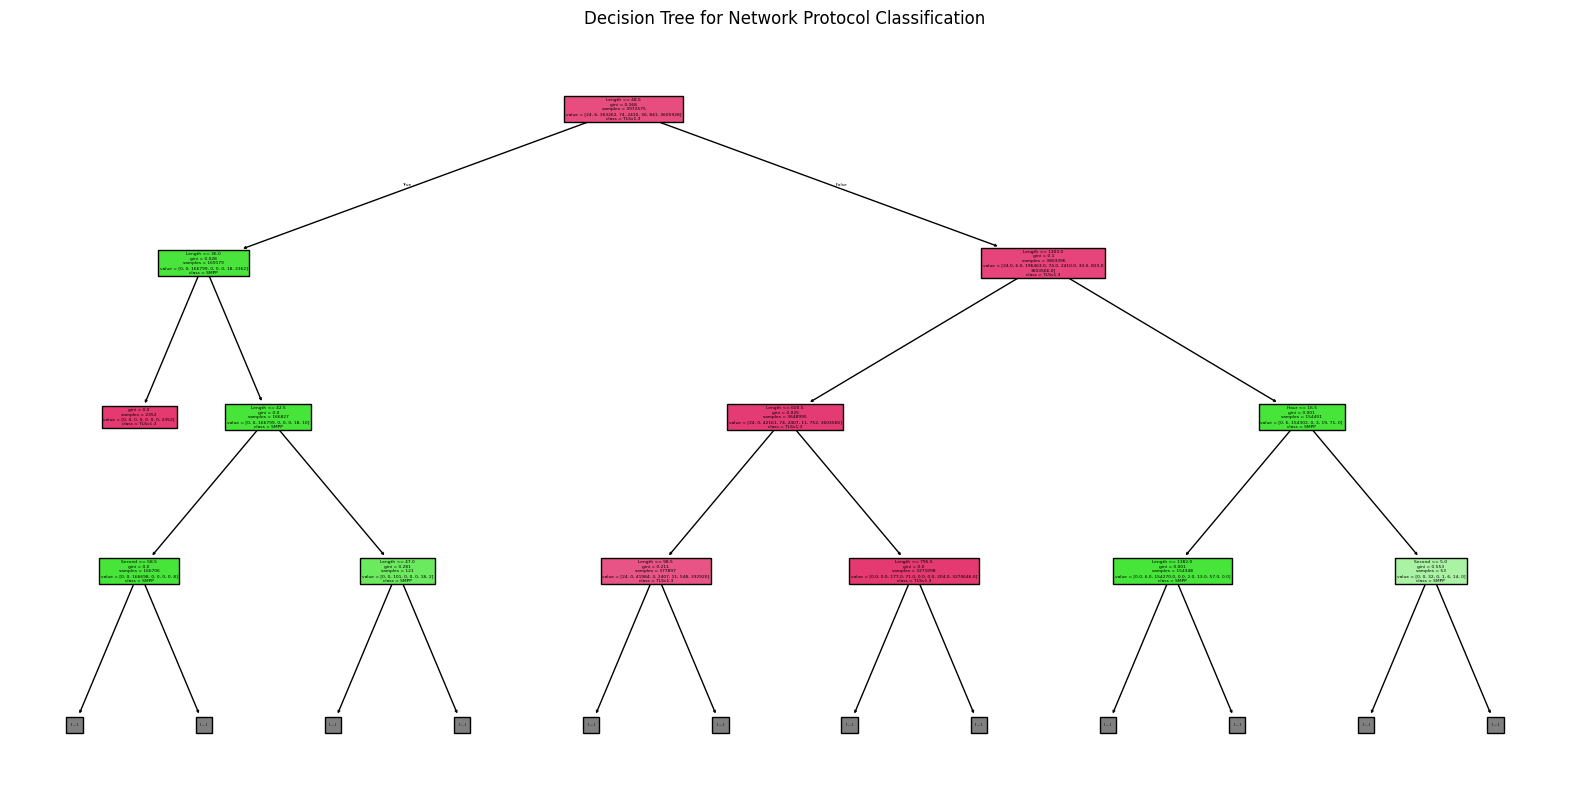

In [189]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3
)

plt.title("Decision Tree for Network Protocol Classification")

plt.show()


## 12. Random Forest Classifier

In [190]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_samples=0.1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(max_depth=10, max_samples=0.1, n_estimators=50,
                       n_jobs=-1, random_state=42)

In [192]:
y_pred_rf = rf_model.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf * 100:.4f}%")

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder_filtered.classes_,
        zero_division=0
    )
)

Random Forest Accuracy: 99.7045%

Classification Report:

              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         6
        SMPP       0.00      0.00      0.00         1
         TCP       0.98      1.00      0.99     90816
      THRIFT       0.00      0.00      0.00        18
       TLSv1       1.00      0.01      0.03       603
     TLSv1.2       0.00      0.00      0.00         8
     TLSv1.3       0.80      0.02      0.04       210
         UDP       1.00      1.00      1.00    901482

    accuracy                           1.00    993144
   macro avg       0.47      0.25      0.26    993144
weighted avg       1.00      1.00      1.00    993144



In [193]:
y_pred_rf = rf_model.predict(X_test)

In [194]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    accuracy_rf * 100,
    "%"
)



Random Forest Accuracy: 99.70447387287241 %


## 13. Model Performance Comparison

In [195]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
)

results


,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.916255,91.625484
1,KNN,0.995600,99.560000
2,Decision Tree,0.998501,99.850072
3,Random Forest,0.997045,99.704474


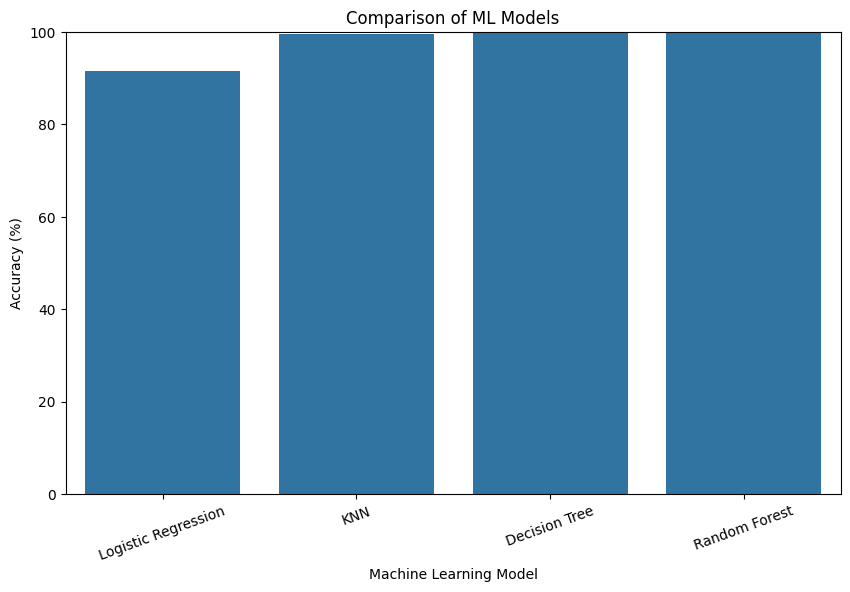

In [196]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.title("Comparison of ML Models")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Model")

plt.show()


In [197]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print("Best Model:")
print(best_model)


Best Model:
Model           Decision Tree
Accuracy             0.998501
Accuracy (%)        99.850072
Name: 2, dtype: object


## 14. Random Forest Feature Importance

In [198]:
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


  Feature  Importance
0  Length    0.987833
1    Hour    0.008184
2  Minute    0.003339
3  Second    0.000643


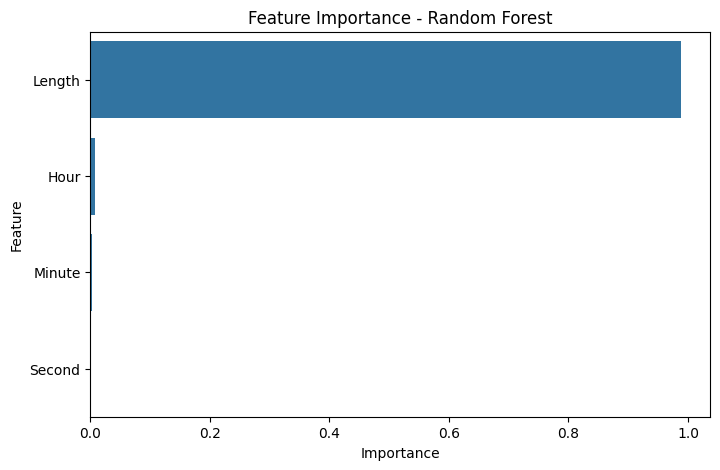

In [199]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")

plt.show()


## 15. Random Forest Evaluation

In [202]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder_filtered.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         DNS       0.00      0.00      0.00         6
        SMPP       0.00      0.00      0.00         1
         TCP       0.98      1.00      0.99     90816
      THRIFT       0.00      0.00      0.00        18
       TLSv1       1.00      0.01      0.03       603
     TLSv1.2       0.00      0.00      0.00         8
     TLSv1.3       0.80      0.02      0.04       210
         UDP       1.00      1.00      1.00    901482

    accuracy                           1.00    993144
   macro avg       0.47      0.25      0.26    993144
weighted avg       1.00      1.00      1.00    993144



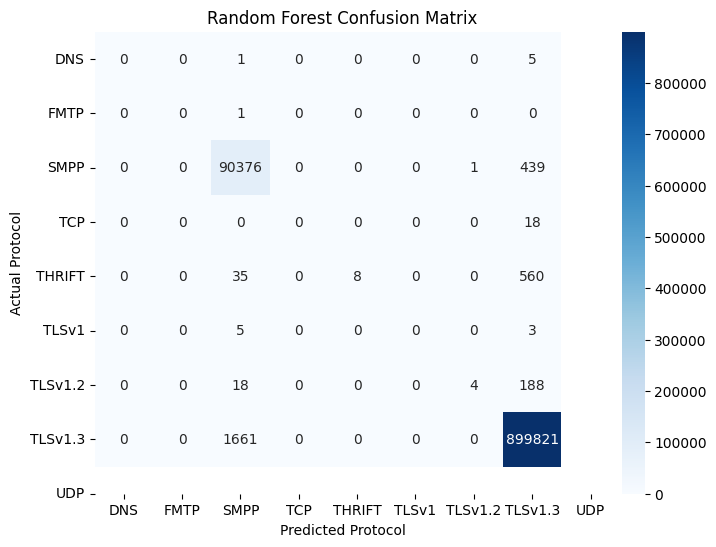

In [203]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()



## 16. Predict the Protocol for a New Packet

In [204]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})


In [205]:
prediction = rf_model.predict(
    new_packet
)


In [207]:
predicted_protocol = label_encoder_filtered.inverse_transform(
    prediction
)

print(
    "Predicted Protocol:",
    predicted_protocol[0]
)

Predicted Protocol: UDP
